<a href="https://colab.research.google.com/github/Flavio008/-tude-de-sant-publique/blob/master/Distribuci%C3%B3nde_los_ingresos_y_la_riqueza_en_distintos_grupos_de_pobleci%C3%B3n_de_Argentina.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Descargar los datos reales de WID para Argentina
url = "https://wid.world/bulk_download/WID_data_AR.csv"

df = pd.read_csv(url, low_memory=False, sep=';')



In [24]:
df.head()

# 2. Ver los nombres de las variables (columnas)
#df.columns
#print(df.columns.tolist())

,country,variable,percentile,year,value,age,pop,data_quality
0,AR,ehfcari999,p0p100,1990,56.711179,999,i,NaN
1,AR,ehfcari999,p0p100,1991,61.134980,999,i,NaN
2,AR,ehfcari999,p0p100,1992,64.665344,999,i,NaN
3,AR,ehfcari999,p0p100,1993,61.909971,999,i,NaN
4,AR,ehfcari999,p0p100,1994,63.590771,999,i,NaN


In [12]:
# 2. Seleccionar la riqueza personal neta media
# ahwealj992 = riqueza neta personal media, adultos, reparto igualitario
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["value"] = pd.to_numeric(df["value"], errors="coerce")

riqueza = df[
    (df["variable"] == "ahwealj992") &
    (df["year"] >= 1995) &
    (df["year"] <= 2025)
].copy()

if riqueza.empty:
    raise ValueError(
        "No se encontró la serie ahwealj992. "
        "Comprueba las variables disponibles en el archivo."
    )




In [13]:
# 3. Grupos de riqueza que queremos comparar
grupos = {
    "p0p50": "50 % más pobre",
    "p50p90": "40 % intermedio",
    "p90p99": "Siguiente 9 %",
    "p99p100": "1 % más rico",
    "p99.9p100": "0,1 % más rico",
    "p99.99p100": "0,01 % más rico",
}

riqueza = riqueza[riqueza["percentile"].isin(grupos)].copy()

# Mostrar qué grupos y años están realmente disponibles
print("Grupos disponibles:")
print(sorted(riqueza["percentile"].dropna().unique()))

print("\nAños disponibles:")
print(sorted(riqueza["year"].dropna().unique()))



Grupos disponibles:
['p0p50', 'p50p90', 'p99.99p100', 'p99.9p100', 'p99p100']

Años disponibles:
[np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [14]:
# 4. Elegir un año final común para los grupos disponibles
tabla = riqueza.pivot_table(
    index="year",
    columns="percentile",
    values="value",
    aggfunc="first"
)

if 1995 not in tabla.index:
    raise ValueError("No hay observación para 1995.")

grupos_validos = [
    g for g in grupos
    if g in tabla.columns and pd.notna(tabla.loc[1995, g])
]

if not grupos_validos:
    raise ValueError("No hay grupos con datos válidos para 1995.")

# Último año con datos para TODOS los grupos elegidos
anios_comunes = tabla[grupos_validos].dropna().index
anios_comunes = anios_comunes[anios_comunes >= 1995]

if len(anios_comunes) == 0:
    raise ValueError("No hay años comunes para comparar los grupos.")

anio_final = int(anios_comunes.max())
print(f"\nPeríodo comparado: 1995-{anio_final}")




Período comparado: 1995-2024


In [16]:
# 5. Calcular la tasa media anual compuesta real
resultados = []

for grupo in grupos_validos:
    inicial = tabla.loc[1995, grupo]
    final = tabla.loc[anio_final, grupo]

    # La tasa compuesta requiere valores inicial y final positivos
    if inicial <= 0 or final <= 0:
        print(f"Se omite {grupo}: riqueza inicial/final no positiva.")
        continue

    tasa = ((final / inicial) ** (1 / (anio_final - 1995)) - 1) * 100

    resultados.append({
        "grupo": grupos[grupo],
        "crecimiento_anual_pct": tasa
    })

res = pd.DataFrame(resultados).sort_values(
    "crecimiento_anual_pct"
)

if res.empty:
    raise ValueError(
        "No se pudo calcular el crecimiento para ningún grupo. "
        "Revisa los valores de riqueza inicial y final."
    )



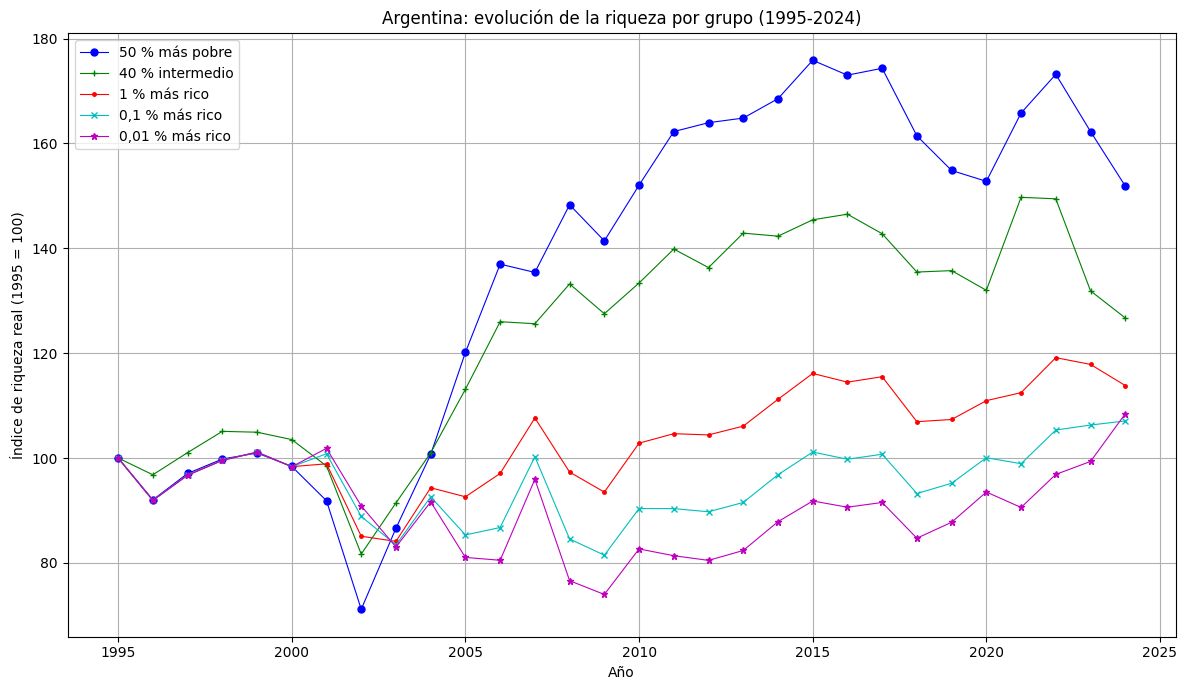

In [19]:
# 6. Crear el gráfico
# 6. Gráfico con marcadores y cuadrícula, sin barras


# Gráfico de líneas con marcadores por grupo de riqueza

fig, ax = plt.subplots(figsize=(12, 7))

marcadores = ["o", "+", ".", "x", "*", "^"]
colores = ["b", "g", "r", "c", "m", "y"]

for i, grupo in enumerate(grupos_validos):
    serie = tabla[grupo].dropna()
    serie = serie.loc[
        (serie.index >= 1995) & (serie.index <= anio_final)
    ]

    if serie.empty:
        continue

    # Índice 1995 = 100 para comparar la evolución relativa
    indice = serie / serie.loc[1995] * 100

    ax.plot(
        indice.index,
        indice.values,
        color=colores[i % len(colores)],
        linewidth=0.8,
        marker=marcadores[i % len(marcadores)],
        markersize=5,
        label=grupos[grupo]
    )

ax.grid(True)
ax.set_xlabel("Año")
ax.set_ylabel("Índice de riqueza real (1995 = 100)")
ax.set_title(
    f"Argentina: evolución de la riqueza por grupo ({1995}-{anio_final})"
)
ax.legend()
plt.tight_layout()

plt.savefig("argentina_evolucion_riqueza.png", dpi=200)
plt.show()




In [ ]:
# 7. Guardar también los resultados calculados
res.to_csv("argentina_crecimiento_riqueza.csv", index=False)

print("\nResultados:")
print(res)
print("\nArchivos creados:")
print("- argentina_crecimiento_riqueza.png")
print("- argentina_crecimiento_riqueza.csv")

Dimensiones: (604450, 8)
Columnas: ['country', 'variable', 'percentile', 'year', 'value', 'age', 'pop', 'data_quality']
  country    variable percentile  year      value  age pop  data_quality
0      AR  ehfcari999     p0p100  1990  56.711179  999   i           NaN
1      AR  ehfcari999     p0p100  1991  61.134980  999   i           NaN
2      AR  ehfcari999     p0p100  1992  64.665344  999   i           NaN
3      AR  ehfcari999     p0p100  1993  61.909971  999   i           NaN
4      AR  ehfcari999     p0p100  1994  63.590771  999   i           NaN


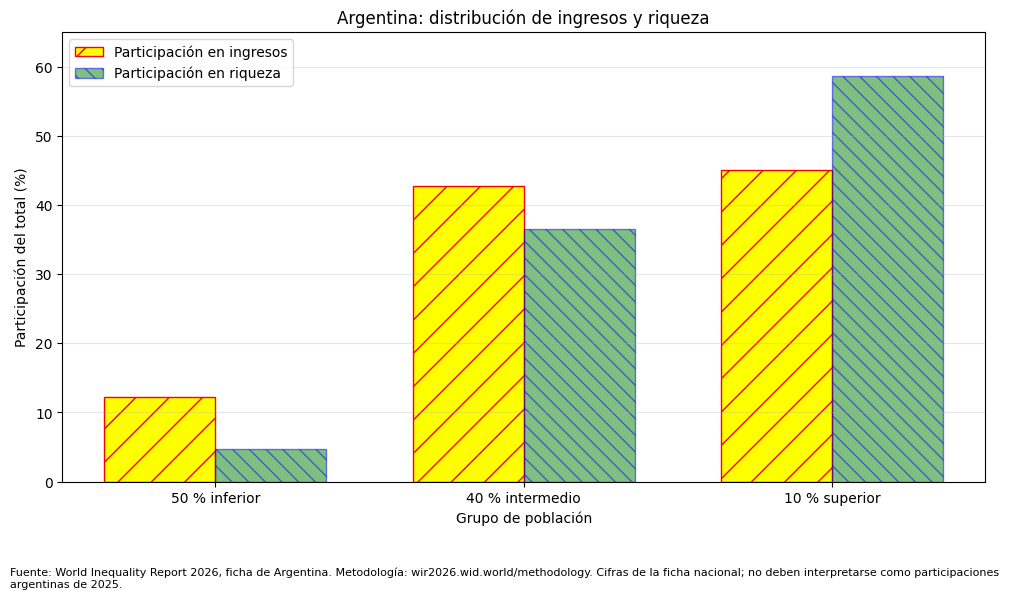

In [23]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Descargar los datos originales de WID para Argentina
url = "https://wid.world/bulk_download/WID_data_AR.csv"
df = pd.read_csv(url, low_memory=False, sep=";")

# 2. Examinar la estructura de los datos descargados
df.columns = df.columns.str.strip()

print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())
print(df.head())

# 3. Porcentajes publicados en la ficha de Argentina
# World Inequality Report 2026
# Participación en el total (%)
grupos = ["50 % inferior", "40 % intermedio", "10 % superior"]

ingresos = [12.2, 42.7, 45.1]
riqueza = [4.7, 36.6, 58.7]

# 4. Crear el gráfico
x = np.arange(len(grupos))
ancho = 0.36

plt.figure(figsize=(10, 6))

plt.bar(
    x - ancho/2, ingresos, ancho,
    label="Participación en ingresos",
    color="yellow", edgecolor="red", hatch="/"
)

plt.bar(
    x + ancho/2, riqueza, ancho,
    label="Participación en riqueza",
    color="green", alpha=0.5,
    edgecolor="blue", hatch="\\\\"
)

plt.ylabel("Participación del total (%)")
plt.xlabel("Grupo de población")
plt.title("Argentina: distribución de ingresos y riqueza")

plt.xticks(x, grupos)
plt.ylim(0, 65)
plt.grid(axis="y", alpha=0.3)
plt.legend()

# 5. Fuente y nota metodológica
plt.figtext(
    0.01, 0.015,
    "Fuente: World Inequality Report 2026, ficha de Argentina. "
    "Metodología: wir2026.wid.world/methodology. "
    "Cifras de la ficha nacional; no deben interpretarse como "
    "participaciones argentinas de 2025.",
    ha="left",
    fontsize=8,
    wrap=True
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

